# Régression sur le prix des annonces Airbnb à Paris

**Question** : les Jeux olympiques et paralympiques de 2024 ont-ils fait monter le prix des annonces Airbnb situées près des sites de compétition ?

**Démarche en deux étapes :**
1. **Régression sur un relevé** : quels facteurs expliquent le prix à un moment donné, et quel est le lien entre prix et distance au site le plus proche ?
2. **Différence de différences** : on suit les mêmes annonces avant et pendant les Jeux, et on compare les annonces proches des sites aux annonces éloignées.
3. **Test placebo** : la même régression qu'à l'étape 1 sur l'été 2026, sans Jeux.
4. **Triple différence** : l'été 2024 comparé à l'été 2026, pour retirer la saisonnalité propre aux quartiers touristiques.
5. **Les avis, semaine par semaine, de 2022 à 2026** : séjours réellement effectués, en temps et en distance continus.

**Sources :**
- Inside Airbnb : relevés mensuels 2024 (stockage de l'équipe) ; relevés publics de juin à septembre 2026 et fichier des avis 2010-2026 (téléchargés par `telecharger_donnees_externes.py`) ;
- ministère chargé des Sports : sites de compétition, via `sites_competition.py` ;
- INSEE : hôtellerie à Paris ; Eurostat : nuitées réservées via les plateformes en Île-de-France.

**Remarque sur les données** : le fichier `listing_16_mars_2024` contient en réalité les données de juin (collectées du 11 au 13 juin), comme `listing_10_juin_2024`. Il n'y a donc pas de relevé de mars utilisable : ce fichier est écarté.

## 0. Préparation

On charge les bibliothèques. `statsmodels` sert à estimer les régressions avec des formules proches de celles de R.

In [1]:
from pathlib import Path
from urllib.parse import quote
from urllib.request import urlretrieve
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

pd.set_option("display.max_columns", 50)

### Relevés Airbnb

Les relevés sont stockés sur le SSP Cloud. Chaque fichier pèse environ 200 Mo : on le télécharge une seule fois dans `donnees_airbnb/` (dossier exclu de git), puis on le relit en local.

On ne garde que les colonnes utiles à l'analyse. Le relevé « mars » est absent du dictionnaire car c'est un doublon de juin.

In [2]:
URL_STOCKAGE = "https://minio.lab.sspcloud.fr/etiennealpy/données paris/"
DOSSIER_AIRBNB = Path("donnees_airbnb")

RELEVES = {
    "janvier": "listing_13_janvier_2024",
    "fevrier": "listing_14_fevrier_2024",
    "avril": "listing_17_avril_2024.csv",
    "mai": "listing_11_mai_2024.csv",
    "juin": "listing_10_juin_2024",
    "juillet": "listing_14_juillet_2024.csv",
    "aout": "listing_09_aout_2024.csv",
    "septembre": "listing_6_septembre_2024",
    "octobre": "listing_07_octobre_2024.csv",
    "novembre": "listing_09_novembre_2024.csv",
    "decembre": "listing_16_decembre_2024",
}

COLONNES = [
    "id", "last_scraped", "latitude", "longitude", "neighbourhood_cleansed",
    "room_type", "accommodates", "bedrooms", "bathrooms", "price",
    "minimum_nights", "number_of_reviews", "review_scores_rating",
    "host_is_superhost", "instant_bookable", "calculated_host_listings_count",
    "availability_30", "number_of_reviews_l30d",
]


def charger_releve(mois):
    """Télécharge le relevé du mois s'il n'est pas déjà en local, puis le lit."""
    nom = RELEVES[mois]
    fichier = DOSSIER_AIRBNB / (nom if nom.endswith(".csv") else nom + ".csv")
    if not fichier.exists():
        DOSSIER_AIRBNB.mkdir(exist_ok=True)
        print(f"Téléchargement de {nom}...")
        urlretrieve(quote(URL_STOCKAGE + nom, safe=":/"), fichier)
    return pd.read_csv(fichier, usecols=COLONNES)

### Sites de compétition

Les sites viennent du script `sites_competition.py` de l'équipe. S'il n'a jamais été lancé, on le lance pour créer le fichier local.

On garde **tous les sites**, olympiques et paralympiques, y compris ceux hors de Paris. Une annonce du 18e arrondissement peut en effet être plus proche du Stade de France (Saint-Denis) que d'un site parisien. Les sites lointains (Marseille, Tahiti…) ne gênent pas : ils ne seront jamais le site le plus proche d'une annonce parisienne.

In [3]:
if not Path("donnees_sites/donnees_nettoyees.csv").exists():
    subprocess.run([sys.executable, "sites_competition.py"], check=True, capture_output=True)

from sites_competition import site_olympiques, site_paralympique

sites = (
    pd.concat([site_olympiques, site_paralympique])
    .dropna(subset=["latitude", "longitude"])
    .drop_duplicates(subset="code_site")
    .reset_index(drop=True)
)
print(f"{len(sites)} sites de compétition distincts")

44 sites de compétition distincts


### Fonctions de distance

On calcule la distance « à vol d'oiseau » sur la sphère terrestre (formule de Haversine), comme dans `prix_en_fonction_de_la_distance.py`.

Le centre de Paris est le point zéro des routes de France, sur le parvis de Notre-Dame.

In [4]:
CENTRE_PARIS = (48.85341, 2.34880)  # point zéro, parvis de Notre-Dame


def distance_km(lat1, lon1, lat2, lon2):
    """Distance de Haversine en km ; accepte des tableaux numpy."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = (np.sin((lat2 - lat1) / 2) ** 2
         + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))


def distance_site_le_plus_proche(annonces, sites):
    """Pour chaque annonce : distance (km) et code du site de compétition le plus proche."""
    # Matrice annonces × sites, puis minimum sur les sites
    d = distance_km(
        annonces["latitude"].to_numpy()[:, None], annonces["longitude"].to_numpy()[:, None],
        sites["latitude"].to_numpy()[None, :], sites["longitude"].to_numpy()[None, :],
    )
    return d.min(axis=1), sites["code_site"].to_numpy()[d.argmin(axis=1)]

### Relevés de l'été 2026

Ces relevés publics d'Inside Airbnb servent de comparaison « sans Jeux ». On utilise seulement **juin à septembre 2026** : les relevés de décembre 2025 à février 2026 n'ont aucun prix, et ceux de mars à mai 2026 ne contiennent qu'environ 39 000 annonces.

**Définition du prix** : en 2026, `price` est le prix par nuit d'un devis pour le premier séjour disponible (en médiane, 6 jours après la collecte). Les relevés 2024 n'ont pas les colonnes de devis, mais la part de prix manquants y est comparable. On suppose donc la même méthode, sans pouvoir le vérifier.

In [5]:
DOSSIER_EXTERNE = Path("donnees_externes/insideairbnb")
RELEVES_2026 = {"juin": "2026-06-16", "juillet": "2026-07-15", "aout": "2026-08-15", "septembre": "2026-09-16"}

if not DOSSIER_EXTERNE.exists():
    subprocess.run([sys.executable, "telecharger_donnees_externes.py"], check=True)


def charger_releve_2026(mois):
    return pd.read_csv(DOSSIER_EXTERNE / f"listings_{RELEVES_2026[mois]}.csv.gz", usecols=COLONNES)

## Contexte : le tourisme à Paris pendant l'été 2024

Avant les régressions, deux séries officielles pour situer l'été des Jeux :
- **INSEE** : taux d'occupation des hôtels parisiens, chaque mois ;
- **Eurostat** : nuitées réservées via Airbnb, Booking et Expedia en Île-de-France, chaque mois.

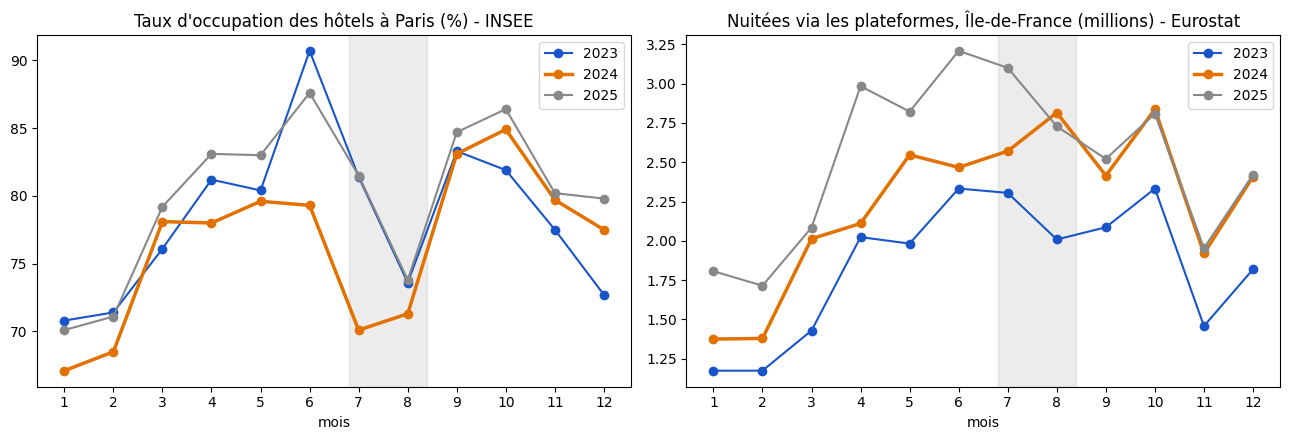

,2023,2024,2025
occupation hôtels (%),,,
juillet,81.4,70.1,81.5
août,73.6,71.3,73.8


In [6]:
import re

xml = Path("donnees_externes/insee_hotellerie_paris.xml").read_text(encoding="utf-8")
series_insee = {}
for attributs, contenu in re.findall(r"<Series ([^>]*)>(.*?)</Series>", xml, re.S):
    titre = re.search(r'TITLE_FR="([^"]*)"', attributs).group(1)
    obs = re.findall(r'TIME_PERIOD="([^"]*)" OBS_VALUE="([^"]*)"', contenu)
    series_insee[titre] = pd.Series({pd.Period(t): float(v) for t, v in obs}).sort_index()
occupation_hotels = next(s for t, s in series_insee.items() if t.startswith("Taux d'occupation"))

eurostat = pd.read_csv("donnees_externes/eurostat_nuitees_plateformes_idf.csv")

ANNEES_CONTEXTE = {2023: "#1855c9", 2024: "#e27100", 2025: "#888888"}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for annee, couleur in ANNEES_CONTEXTE.items():
    s = occupation_hotels[occupation_hotels.index.year == annee]
    axes[0].plot(s.index.month, s.values, marker="o", color=couleur, label=annee, linewidth=2.5 if annee == 2024 else 1.5)
    e = eurostat[eurostat["annee"] == annee]
    axes[1].plot(e["mois"], e["nuitees"] / 1e6, marker="o", color=couleur, label=annee, linewidth=2.5 if annee == 2024 else 1.5)
for ax in axes:
    ax.axvspan(6.8, 8.4, color="grey", alpha=0.15)
    ax.set_xticks(range(1, 13))
    ax.set_xlabel("mois")
    ax.legend()
axes[0].set_title("Taux d'occupation des hôtels à Paris (%) - INSEE")
axes[1].set_title("Nuitées via les plateformes, Île-de-France (millions) - Eurostat")
fig.tight_layout()
plt.show()

pd.DataFrame({annee: occupation_hotels[occupation_hotels.index.year == annee].values[6:8] for annee in ANNEES_CONTEXTE},
             index=["juillet", "août"]).rename_axis("occupation hôtels (%)")

**Commentaire** :

L'été 2024 se distingue nettement, mais pas de la même façon pour les hôtels et pour les plateformes.

- **Hôtels** : leur taux d'occupation décroche dès juin 2024 (79 %, contre 91 % en 2023 et 88 % en 2025). Il reste très bas en juillet : 70,1 %, contre 81,4 % et 81,5 %, soit environ 11 points de moins. En août, l'écart se referme presque (71,3 % contre 73,6 % et 73,8 %). Dès septembre, 2024 revient au niveau des autres années. Une partie des touristes habituels a donc évité Paris juste avant et pendant les JO (prix élevés, crainte de la foule, périmètres de sécurité) : c'est un **effet d'éviction**.
- **Plateformes** (Airbnb, Booking, Expedia en Île-de-France) : les nuitées augmentent pendant l'été 2024. En juillet, elles atteignent 2,57 millions, contre 2,31 en 2023 (+12 %). En août, elles atteignent 2,82 millions, contre 2,01 en 2023 (+40 %). C'est même plus qu'en août 2025 (2,73 millions), alors que la série progresse fortement d'une année sur l'autre. Août 2024 est le seul mois où 2024 dépasse 2025.

Les deux secteurs évoluent donc en sens opposés : les hôtels perdent des clients en juin-juillet, tandis que les locations de courte durée gagnent des nuitées, surtout en août. Prudence : la série Eurostat couvre toute l'Île-de-France et toutes les plateformes, et sa forte tendance à la hausse rend la comparaison avec 2023 favorable à 2024.

## 1. Étape 1 : régression sur un relevé

**Choix retenus :**
- **Relevés** : la même régression sur juin (`listing_10_juin_2024`, collecté du 11 au 13 juin, avant les Jeux) et sur juillet (`listing_14_juillet_2024`, collecté du 15 au 19 juillet, juste avant l'ouverture), pour comparer les deux résultats.
- **Proximité** : tranches de distance au site de compétition le plus proche : moins de 1 km, 1 à 3 km, plus de 3 km (référence).
- **Annonces** : toutes, avec le type de logement (`room_type`) comme variable de contrôle.
- **Emplacement** : effets fixes arrondissement **et** distance au centre de Paris.

### 1.1 Préparation des données

Pour chaque relevé :

1. **Prix** : le texte `"$1,234.00"` devient le nombre 1234. Les annonces sans prix (environ 22 %, souvent inactives) sont retirées.
2. **Prix extrêmes** : on retire les 1 % les moins chers et les 1 % les plus chers. Certaines annonces affichent jusqu'à 90 000 € la nuit, ce qui fausserait les moyennes.
3. **Proximité** : distance au site le plus proche, puis découpage en trois tranches. « Plus de 3 km » sert de référence.
4. **Contrôles** :
   - taille du logement : voyageurs, chambres, salles de bain ;
   - type de logement ;
   - avis : note et nombre d'avis ;
   - hôte : Superhôte, réservation instantanée, nombre minimum de nuits, hôte qui gère plusieurs annonces ;
   - emplacement : arrondissement et distance au centre.
5. **Annonces sans note** (environ un tiers) : on ne les retire pas. On leur attribue la note moyenne et on ajoute une variable `sans_note`, qui vaut 1 pour elles. Le coefficient de `sans_note` mesure l'écart de prix des annonces sans note.

In [7]:
TRANCHES = ["moins de 1 km", "1 à 3 km", "plus de 3 km"]


def preparer(annonces, sites):
    df = annonces.copy()

    # 1. Prix en nombre, annonces sans prix retirées
    df["prix"] = pd.to_numeric(df["price"].str.replace(r"[$,]", "", regex=True), errors="coerce")
    n_depart = len(df)
    df = df.dropna(subset=["prix"])

    # 2. Retrait des 1 % de prix les plus bas et les plus hauts
    bas, haut = df["prix"].quantile([0.01, 0.99])
    df = df[df["prix"].between(bas, haut)]
    df["log_prix"] = np.log(df["prix"])

    # 3. Distance au site le plus proche et tranches
    df["dist_site_km"], df["site_proche"] = distance_site_le_plus_proche(df, sites)
    df["tranche"] = pd.cut(df["dist_site_km"], bins=[0, 1, 3, np.inf], labels=TRANCHES, right=False)
    df["dist_centre_km"] = distance_km(df["latitude"], df["longitude"], *CENTRE_PARIS)

    # 4. Variables de contrôle
    df["arrondissement"] = df["neighbourhood_cleansed"]
    df["sans_note"] = df["review_scores_rating"].isna().astype(int)
    df["note"] = df["review_scores_rating"].fillna(df["review_scores_rating"].mean())
    df["log_nb_avis"] = np.log1p(df["number_of_reviews"])
    df["log_nuits_min"] = np.log(df["minimum_nights"].clip(lower=1))
    df["superhote"] = (df["host_is_superhost"] == "t").astype(int)
    df["resa_instantanee"] = (df["instant_bookable"] == "t").astype(int)
    df["hote_multi_annonces"] = (df["calculated_host_listings_count"] > 1).astype(int)

    # Les rares lignes sans chambres ou salles de bain renseignées sont retirées
    df = df.dropna(subset=["bedrooms", "bathrooms"])
    print(f"{n_depart} annonces -> {len(df)} gardées (prix entre {bas:.0f} € et {haut:.0f} €)")
    return df


donnees = {}
for mois in ["juin", "juillet"]:
    print(mois, end=" : ")
    donnees[mois] = preparer(charger_releve(mois), sites)

juin : 

95885 annonces -> 72976 gardées (prix entre 43 € et 2000 €)
juillet : 

98810 annonces -> 75358 gardées (prix entre 42 € et 1853 €)


### 1.2 Premier regard : prix médian par tranche de distance

Avant la régression, on regarde les chiffres bruts : nombre d'annonces et prix médian dans chaque tranche, en juin et en juillet.

In [8]:
resume = pd.concat(
    {mois: df.groupby("tranche", observed=True)["prix"].agg(annonces="size", prix_median="median")
     for mois, df in donnees.items()},
    axis=1,
)
resume

juin              juillet            
              annonces prix_median annonces prix_median
tranche                                                
moins de 1 km    15986       200.0    16606       191.0
1 à 3 km         53277       159.0    54915       150.0
plus de 3 km      3713       120.0     3837       121.0

**Commentaire** :

Les écarts bruts sont importants. En juin, le prix médian est de 200 € à moins de 1 km d'un site, 159 € entre 1 et 3 km et 120 € au-delà de 3 km, soit +67 % entre la première et la dernière tranche. Juillet donne le même classement (191 €, 150 €, 121 €), avec un prix médian proche des sites qui baisse légèrement.

Ces chiffres ne mesurent pas un effet des Jeux :
- la tranche « plus de 3 km » est petite (environ 3 700 annonces, 5 %), car presque tout Paris est à moins de 3 km d'un site. Elle regroupe surtout des annonces en bordure de Paris ;
- les annonces proches des sites sont surtout dans le centre et les quartiers touristiques (Concorde, Tour Eiffel, Invalides, Grand Palais), où les logements sont plus chers de toute façon.

La régression doit séparer la proximité d'un site de ces autres facteurs.

### 1.3 Le modèle

$$\log(\text{prix}_i) = \beta_1 \cdot \mathbb{1}[< 1\text{ km}]_i + \beta_2 \cdot \mathbb{1}[1\text{-}3\text{ km}]_i + \gamma \cdot \text{distance au centre}_i + \text{contrôles}_i + \text{effet fixe arrondissement}_i + \varepsilon_i$$

- **Lecture de β₁** : à caractéristiques égales, une annonce à moins de 1 km d'un site coûte environ $(e^{\beta_1} - 1) \times 100$ % de plus qu'une annonce à plus de 3 km, dans le même arrondissement.
- **Erreurs standard robustes (HC1)** : les écarts de prix ne sont pas les mêmes pour tous les logements (un studio et un grand appartement ne varient pas autant). Ces erreurs standard en tiennent compte, pour que les tests restent fiables.
- **Rappel de la limite** : dans un relevé seul, β₁ mesure une **corrélation**. Les sites sont dans des lieux touristiques (tour Eiffel, Concorde…), et une partie de l'écart peut venir de là même sans les Jeux. C'est la comparaison entre mois de l'étape 2 qui isole l'effet des Jeux.

In [9]:
FORMULE = (
    "log_prix ~ C(tranche, Treatment('plus de 3 km'))"
    " + dist_centre_km"
    " + C(room_type) + accommodates + bedrooms + bathrooms"
    " + note + sans_note + log_nb_avis"
    " + superhote + resa_instantanee + log_nuits_min + hote_multi_annonces"
    " + C(arrondissement)"
)

modeles = {mois: smf.ols(FORMULE, data=df).fit(cov_type="HC1") for mois, df in donnees.items()}

for mois, m in modeles.items():
    print(f"{mois} : {int(m.nobs)} annonces, R² = {m.rsquared:.3f}")

juin : 72976 annonces, R² = 0.481
juillet : 75358 annonces, R² = 0.439


### 1.4 Résultats

Tableau des coefficients, sans les effets fixes arrondissement. La colonne « effet en % » traduit le coefficient en écart de prix : $(e^{\beta} - 1) \times 100$.

In [10]:
def tableau(modele):
    t = pd.DataFrame({
        "coef": modele.params,
        "erreur std": modele.bse,
        "p-valeur": modele.pvalues,
        "effet en %": (np.exp(modele.params) - 1) * 100,
    })
    t.loc["Intercept", "effet en %"] = np.nan  # sans interprétation pour la constante
    t = t[~t.index.str.startswith("C(arrondissement)")]
    t.index = (t.index
               .str.replace(r"C\(tranche, Treatment\('plus de 3 km'\)\)\[T\.(.*)\]", r"site à \1", regex=True)
               .str.replace(r"C\(room_type\)\[T\.(.*)\]", r"type : \1", regex=True))
    return t.round(4)


pd.concat({mois: tableau(m) for mois, m in modeles.items()}, axis=1)

juin                                juillet  \
                        coef erreur std p-valeur effet en %    coef   
Intercept             4.1915     0.0405   0.0000        NaN  4.0895   
site à moins de 1 km  0.0527     0.0123   0.0000     5.4099  0.0387   
site à 1 à 3 km       0.0168     0.0104   0.1070     1.6903  0.0020   
type : Hotel room     0.4822     0.0199   0.0000    61.9650  0.2678   
type : Private room  -0.1667     0.0088   0.0000   -15.3564 -0.1909   
type : Shared room   -0.4486     0.0456   0.0000   -36.1506 -0.4040   
dist_centre_km       -0.0936     0.0036   0.0000    -8.9382 -0.0808   
accommodates          0.1354     0.0073   0.0000    14.4951  0.1128   
bedrooms              0.1583     0.0147   0.0000    17.1552  0.1956   
bathrooms             0.0911     0.0301   0.0025     9.5399  0.1116   
note                  0.1503     0.0071   0.0000    16.2218  0.1601   
sans_note             0.2772     0.0062   0.0000    31.9434  0.2176   
log_nb_avis          -0.0278     0.0018   0.0000    -2.7425 -0.0219   
superhote             0.0568     0.0049   0.0000     5.8477  0.0409   
resa_instantanee      0.0100     0.0050   0.0455     1.0013 -0.0592   
log_nuits_min        -0.0957     0.0020   0.0000    -9.1307 -0.0674   
hote_multi_annonces  -0.0763     0.0048   0.0000    -7.3479 -0.1330   

                                                     
                     erreur std p-valeur effet en %  
Intercept                0.0409   0.0000        NaN  
site à moins de 1 km     0.0123   0.0016     3.9510  
site à 1 à 3 km          0.0104   0.8499     0.1979  
type : Hotel room        0.0237   0.0000    30.7032  
type : Private room      0.0086   0.0000   -17.3818  
type : Shared room       0.0493   0.0000   -33.2354  
dist_centre_km           0.0036   0.0000    -7.7605  
accommodates             0.0072   0.0000    11.9366  
bedrooms                 0.0136   0.0000    21.6047  
bathrooms                0.0288   0.0001    11.8081  
note                     0.0071   0.0000    17.3625  
sans_note                0.0063   0.0000    24.3087  
log_nb_avis              0.0017   0.0000    -2.1674  
superhote                0.0049   0.0000     4.1749  
resa_instantanee         0.0049   0.0000    -5.7520  
log_nuits_min            0.0020   0.0000    -6.5212  
hote_multi_annonces      0.0047   0.0000   -12.4568

### 1.5 Juin et juillet côte à côte

Le graphique montre l'écart de prix des deux tranches proches par rapport à « plus de 3 km », avec son intervalle de confiance à 95 %.

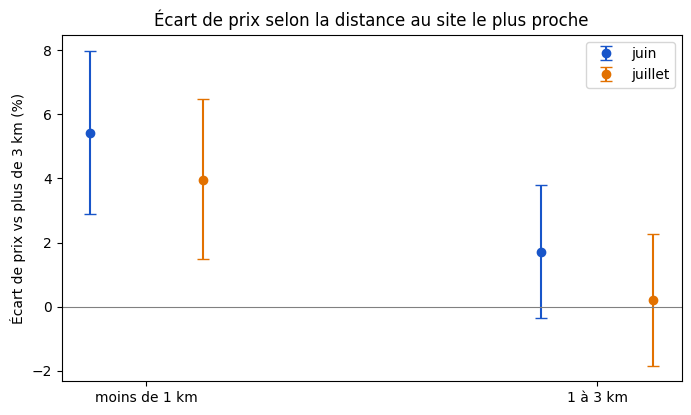

,mois,tranche,effet,bas,haut
0,juin,moins de 1 km,5.4,2.9,8.0
1,juin,1 à 3 km,1.7,-0.4,3.8
2,juillet,moins de 1 km,4.0,1.5,6.5
3,juillet,1 à 3 km,0.2,-1.8,2.3


In [11]:
lignes = []
for mois, m in modeles.items():
    ic = m.conf_int()
    for tranche in ["moins de 1 km", "1 à 3 km"]:
        nom = f"C(tranche, Treatment('plus de 3 km'))[T.{tranche}]"
        lignes.append({
            "mois": mois, "tranche": tranche,
            "effet": (np.exp(m.params[nom]) - 1) * 100,
            "bas": (np.exp(ic.loc[nom, 0]) - 1) * 100,
            "haut": (np.exp(ic.loc[nom, 1]) - 1) * 100,
        })
effets = pd.DataFrame(lignes)

fig, ax = plt.subplots(figsize=(8, 4.5))
for i, (mois, couleur) in enumerate([("juin", "#1855c9"), ("juillet", "#e27100")]):
    e = effets[effets["mois"] == mois]
    x = np.arange(len(e)) + (i - 0.5) * 0.25
    ax.errorbar(x, e["effet"], yerr=[e["effet"] - e["bas"], e["haut"] - e["effet"]],
                fmt="o", capsize=4, color=couleur, label=mois)
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xticks(range(2), ["moins de 1 km", "1 à 3 km"])
ax.set_ylabel("Écart de prix vs plus de 3 km (%)")
ax.set_title("Écart de prix selon la distance au site le plus proche")
ax.legend()
plt.show()

effets.round(1)

**Commentaire** :

- **Proximité d'un site** : à caractéristiques égales et dans le même arrondissement, une annonce à moins de 1 km d'un site est **5,4 % plus chère** en juin (IC 95 % : 2,9 à 8,0) et **4,0 % plus chère** en juillet (1,5 à 6,5) qu'une annonce à plus de 3 km. Entre 1 et 3 km, l'écart n'est pas significatif (+1,7 % en juin, p = 0,11 ; +0,2 % en juillet).
- **Juin contre juillet** : l'écart n'augmente pas à l'approche de l'ouverture des Jeux. Il est même légèrement plus faible en juillet, et les deux intervalles se recoupent largement. Rien n'indique donc une hausse des prix propre aux annonces proches juste avant les JO. La prime semble exister dès juin : elle pourrait venir de l'emplacement plutôt que des Jeux, ce que teste la section 3.
- **Autres coefficients** (juin / juillet) : ils ont tous le signe attendu.
  - Une personne accueillie en plus : +14 % / +12 %. Une chambre en plus : +17 % / +22 %. Une salle de bain en plus : +10 % / +12 %.
  - Chambre privée : −15 % / −17 % par rapport à un logement entier. Chambre partagée : −36 % / −33 %. Les chambres d'hôtel sont plus chères (+62 % / +31 %).
  - Chaque kilomètre d'éloignement du centre : −9 % / −8 %, en plus des effets fixes d'arrondissement.
  - Note : +16 % / +17 % par point. Les annonces sans note sont plus chères (+32 % / +24 %) : ce sont des annonces récentes ou peu réservées, qui affichent peut-être des prix ambitieux. Plus une annonce a d'avis, moins elle est chère : les annonces très réservées pratiquent des prix plus bas.
  - Superhôte : +6 % / +4 %. Nuits minimum plus longues : prix par nuit plus bas. Les hôtes multi-annonces (gestionnaires professionnels) sont moins chers (−7 % / −12 %).
  - La réservation instantanée change de signe (+1 % en juin, −6 % en juillet).
- **Qualité de l'ajustement** : le modèle explique 48 % (juin) et 44 % (juillet) de la variance du log du prix.

Une différence entre juin et juillet donne une **première indication**. Pour la tester proprement, il faut suivre les mêmes annonces d'un mois à l'autre et comparer à un groupe témoin : c'est l'étape 2.

## 2. Étape 2 : différence de différences

**Choix retenus :**
- **Périodes** : tous les relevés de 2024 (sauf le faux « mars »), avec un effet estimé mois par mois. Les mois d'avant les Jeux servent de vérification : l'effet doit y être proche de zéro.
- **Groupes** : annonces à moins de 1 km d'un site (groupe exposé, environ 22 % des annonces) contre annonces à plus de 2 km (groupe témoin, environ 32 %). Les annonces entre 1 et 2 km sont retirées.
  Le seuil initial de 3 km a été abandonné : il ne laissait qu'environ 5 % des annonces (≈ 3 900), toutes en périphérie, parce que presque tout Paris est à moins de 3 km d'un site.
- **Variables expliquées** :
  - le prix, en log ;
  - l'occupation, mesurée par `1 - availability_30/30` (nuits réservées ou bloquées par l'hôte) ;
  - les avis récents (`number_of_reviews_l30d`), qui signalent des séjours effectués ;
  - la présence de l'annonce en ligne, pour repérer les annonces créées ou retirées autour des Jeux.
- **Annonces suivies** : toutes, y compris celles présentes seulement certains mois ; l'effet fixe annonce compare chaque logement à lui-même.

### 2.1 Construction du panel : une ligne par annonce et par mois

On empile les 11 relevés de 2024. Le numéro du mois sert d'indice de temps ; il n'y a pas de mois 3, puisque le fichier « mars » est un doublon de juin.

Le relevé « juillet » a été collecté du 14 au 28 juillet, donc en grande partie juste avant la cérémonie d'ouverture du 26 juillet. Le relevé « août » (9-15 août) tombe à la fin des Jeux olympiques, et celui de « septembre » (6-13 septembre) pendant la fin des Jeux paralympiques.

In [12]:
NUM_MOIS = {
    "janvier": 1, "fevrier": 2, "avril": 4, "mai": 5, "juin": 6, "juillet": 7,
    "aout": 8, "septembre": 9, "octobre": 10, "novembre": 11, "decembre": 12,
}

releves = []
for mois, num in NUM_MOIS.items():
    r = charger_releve(mois)
    r["mois"] = num
    releves.append(r)
panel = pd.concat(releves, ignore_index=True).drop_duplicates(subset=["id", "mois"])

print(f"{len(panel)} lignes, {panel['id'].nunique()} annonces différentes")
panel.groupby("mois").size().rename("annonces en ligne").to_frame().T

1003623 lignes, 125291 annonces différentes


mois,1,2,4,5,6,7,8,9,10,11,12
annonces en ligne,76938,80545,88548,92665,95885,98810,98736,95461,93275,91729,91031


### 2.2 Groupe proche et groupe témoin

Airbnb décale légèrement la position affichée des logements, et elle peut varier d'un relevé à l'autre. On fixe donc **une position par annonce**, la médiane de ses positions sur l'année, et on calcule sa distance au site le plus proche.

- **proche** : moins de 1 km d'un site ;
- **témoin** : plus de 2 km ;
- les annonces entre 1 et 2 km sont retirées.

In [13]:
positions = panel.groupby("id")[["latitude", "longitude"]].median()
positions["dist_site_km"], positions["site_proche"] = distance_site_le_plus_proche(positions, sites)
positions["groupe"] = np.select(
    [positions["dist_site_km"] < 1, positions["dist_site_km"] > 2],
    ["proche", "témoin"],
    default="intermédiaire",
)
positions["groupe"].value_counts().to_frame("annonces")

,annonces
groupe,
intermédiaire,57220
témoin,41122
proche,26949


### 2.3 Les quatre variables étudiées

- **`log_prix`** : log du prix affiché. Comme à l'étape 1, on retire les prix extrêmes, mais avec des bornes **communes à tous les mois**. Des bornes calculées mois par mois effaceraient justement les hausses de prix de l'été.
- **`occupation`** : `1 - availability_30 / 30`, la part des 30 nuits suivant le relevé qui ne sont pas disponibles. Ce sont des nuits réservées **ou bloquées par l'hôte** : c'est donc une mesure imparfaite de l'occupation.
- **`avis_30j`** : nombre d'avis laissés dans les 30 jours précédant le relevé. Un avis suppose un séjour effectué ; c'est une mesure plus fiable des locations réelles, avec un léger décalage (les voyageurs laissent leur avis quelques jours après le séjour).
- **`en_ligne`** : vaut 1 si l'annonce est présente dans le relevé du mois, 0 sinon. Pour cette variable, on crée une ligne pour chaque annonce et chaque mois, même quand l'annonce est absente. On peut ainsi voir des annonces apparaître ou disparaître autour des Jeux.

In [14]:
panel["prix"] = pd.to_numeric(panel["price"].str.replace(r"[$,]", "", regex=True), errors="coerce")
bas, haut = panel["prix"].quantile([0.01, 0.99])
panel["log_prix"] = np.log(panel["prix"].where(panel["prix"].between(bas, haut)))
panel["occupation"] = 1 - panel["availability_30"] / 30
panel["avis_30j"] = panel["number_of_reviews_l30d"]
panel["en_ligne"] = 1
print(f"Prix gardés entre {bas:.0f} € et {haut:.0f} €")

# Grille complète annonce × mois (proches et témoins seulement)
ids = positions.index[positions["groupe"] != "intermédiaire"]
grille = pd.MultiIndex.from_product([ids, list(NUM_MOIS.values())], names=["id", "mois"]).to_frame(index=False)
grille = grille.merge(panel[["id", "mois", "prix", "log_prix", "occupation", "avis_30j", "en_ligne"]],
                      on=["id", "mois"], how="left")
grille["en_ligne"] = grille["en_ligne"].fillna(0)
grille = grille.merge(positions[["groupe"]], left_on="id", right_index=True)
grille["proche"] = (grille["groupe"] == "proche").astype(int)
print(f"Grille : {len(grille)} lignes ({len(ids)} annonces × {len(NUM_MOIS)} mois)")

Prix gardés entre 42 € et 1957 €
Grille : 748781 lignes (68071 annonces × 11 mois)


### 2.4 Premier regard : évolution brute des deux groupes

Avant toute régression, on trace la moyenne de chaque variable, mois par mois, pour les deux groupes. La différence de différences repose sur une hypothèse : **sans les Jeux, les deux groupes auraient évolué de la même façon**. Les mois de janvier à juin permettent de le vérifier à l'œil : les courbes doivent y être à peu près parallèles.

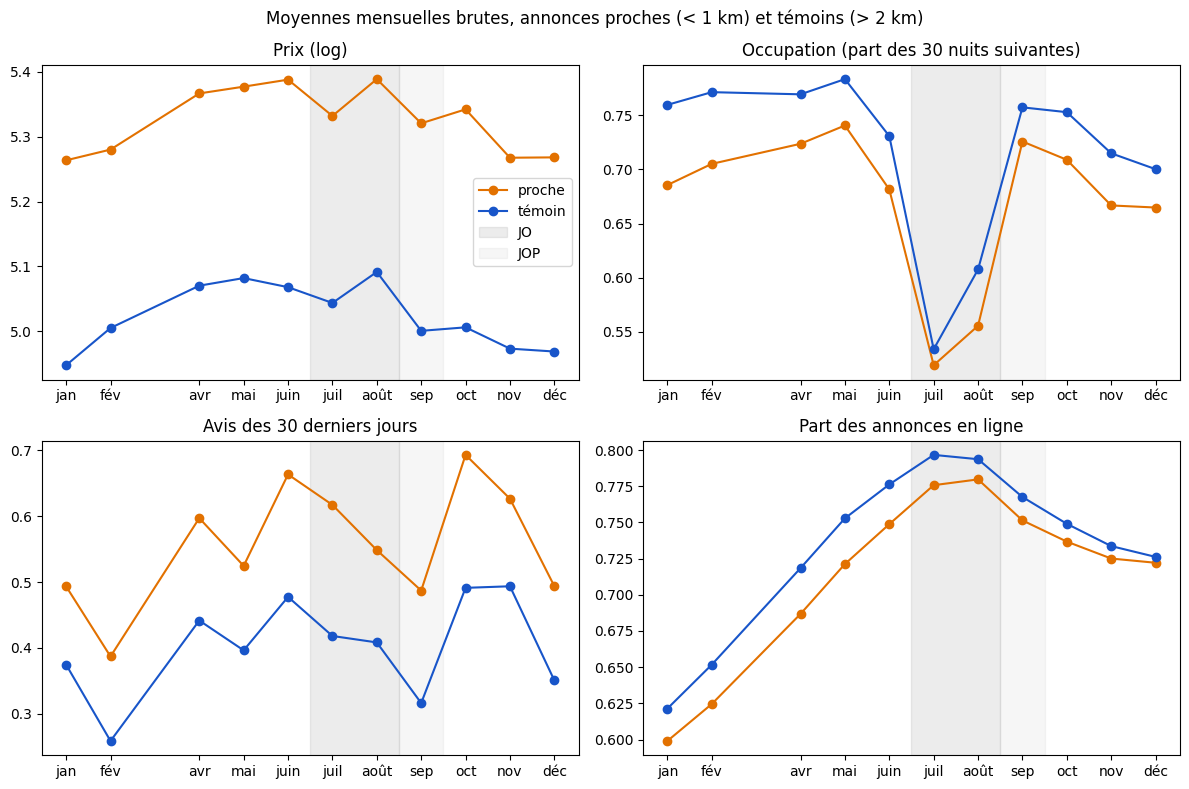

In [15]:
VARIABLES = {
    "log_prix": "Prix (log)",
    "occupation": "Occupation (part des 30 nuits suivantes)",
    "avis_30j": "Avis des 30 derniers jours",
    "en_ligne": "Part des annonces en ligne",
}
COULEURS = {"proche": "#e27100", "témoin": "#1855c9"}
ETIQUETTES_MOIS = ["jan", "fév", "avr", "mai", "juin", "juil", "août", "sep", "oct", "nov", "déc"]


def zones_jeux(ax):
    """Grise la période des Jeux olympiques (juillet-août) et paralympiques (septembre)."""
    ax.axvspan(6.5, 8.5, color="grey", alpha=0.15, label="JO")
    ax.axvspan(8.5, 9.5, color="grey", alpha=0.07, label="JOP")
    ax.set_xticks(list(NUM_MOIS.values()), ETIQUETTES_MOIS)


fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (var, titre) in zip(axes.flat, VARIABLES.items()):
    moyennes = grille.groupby(["mois", "groupe"])[var].mean().unstack()
    for groupe, couleur in COULEURS.items():
        ax.plot(moyennes.index, moyennes[groupe], marker="o", color=couleur, label=groupe)
    zones_jeux(ax)
    ax.set_title(titre)
axes[0, 0].legend()
fig.suptitle("Moyennes mensuelles brutes, annonces proches (< 1 km) et témoins (> 2 km)")
fig.tight_layout()
plt.show()

**Commentaire** :

- **Prix** : les annonces proches sont toujours plus chères que les témoins, d'environ 0,30 en log (environ +35 %). L'écart varie avant les Jeux : 0,32 en janvier, 0,28 en février, environ 0,30 en avril-mai, puis 0,32 en juin. Les courbes ne sont donc pas parfaitement parallèles. En juillet, les deux groupes baissent, les annonces proches un peu plus fortement. En août, les deux remontent.
- **Occupation** : c'est le graphique le plus frappant. Les deux groupes s'effondrent en juillet, de 0,68-0,73 à environ 0,52-0,53, puis remontent en août et retrouvent leur niveau en septembre. Le relevé de juillet regarde les 30 nuits suivantes, c'est-à-dire la période des Jeux : beaucoup de nuits pendant les JO sont restées libres, pour les deux groupes. Les annonces proches, habituellement moins occupées que les témoins (environ 5 points d'écart), les rattrapent presque en juillet (environ 1,5 point d'écart).
- **Avis** : les annonces proches reçoivent toujours plus d'avis. Les deux groupes baissent pendant l'été, sans rupture visible propre aux annonces proches.
- **Présence en ligne** : les deux courbes sont presque parallèles toute l'année, avec un pic en juillet-août. Beaucoup d'hôtes, proches ou non, ont mis leur logement en ligne pour l'été des Jeux.

### 2.5 Le modèle : effet mois par mois

$$y_{it} = \sum_{m \neq \text{juin}} \delta_m \cdot \text{proche}_i \cdot \mathbb{1}[t = m] + \alpha_i + \lambda_t + \varepsilon_{it}$$

- **$\alpha_i$, effet fixe annonce** : chaque logement est comparé à lui-même. Emplacement, taille et standing sont donc pris en compte d'office.
- **$\lambda_t$, effet fixe mois** : retire ce qui touche tout Paris un mois donné, comme la saisonnalité ou la hausse générale de l'été.
- **$\delta_m$** : écart **supplémentaire** des annonces proches par rapport aux témoins le mois $m$, **comparé à juin** (mois de référence, juste avant les Jeux).
  - Avant juin, les $\delta_m$ doivent être proches de zéro : c'est la vérification de l'hypothèse des tendances parallèles.
  - En juillet-août, $\delta_m$ mesure l'effet des Jeux.
- **Erreurs standard regroupées par annonce** : les observations d'un même logement d'un mois à l'autre ne sont pas indépendantes. Les erreurs standard en tiennent compte.

Pour le prix, on interprète $(e^{\delta} - 1) \times 100$ comme un écart en %.

In [16]:
from linearmodels.panel import PanelOLS

MOIS_REF = NUM_MOIS["juin"]
AUTRES_MOIS = [m for m in NUM_MOIS.values() if m != MOIS_REF]


def etude_evenement(var):
    """Différence de différences mois par mois, juin en référence."""
    d = grille.dropna(subset=[var]).copy()
    for m in AUTRES_MOIS:
        d[f"proche_x_{m}"] = d["proche"] * (d["mois"] == m)
    d = d.set_index(["id", "mois"])
    exog = d[[f"proche_x_{m}" for m in AUTRES_MOIS]]
    return PanelOLS(d[var], exog, entity_effects=True, time_effects=True).fit(
        cov_type="clustered", cluster_entity=True
    )


resultats = {var: etude_evenement(var) for var in VARIABLES}
for var, r in resultats.items():
    print(f"{var:12s} : {int(r.nobs)} observations, {r.entity_info['total']:.0f} annonces")

log_prix     : 382169 observations, 57798 annonces
occupation   : 544701 observations, 68071 annonces
avis_30j     : 544701 observations, 68071 annonces
en_ligne     : 748781 observations, 68071 annonces


### 2.6 Résultats : effet des Jeux mois par mois

Chaque point est l'écart supplémentaire des annonces proches par rapport aux témoins, comparé à juin, avec son intervalle de confiance à 95 %. Les points sont exprimés :
- en **%** pour le prix ;
- en **points de pourcentage** pour l'occupation et la présence en ligne ;
- en **nombre d'avis** pour les avis.

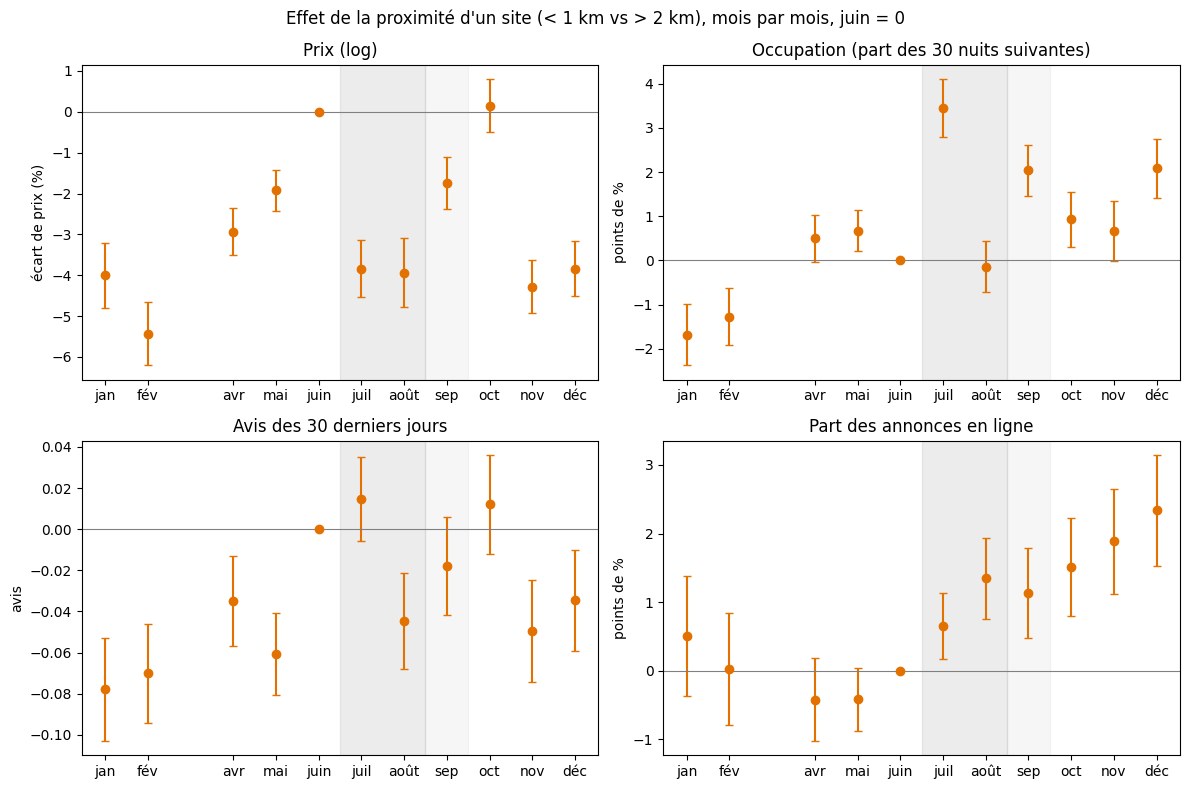

log_prix                        occupation                         \
        effet    bas   haut p-valeur      effet    bas   haut p-valeur   
mois                                                                     
1      -4.006 -4.802 -3.203    0.000     -1.678 -2.371 -0.985    0.000   
2      -5.437 -6.202 -4.666    0.000     -1.278 -1.923 -0.633    0.000   
4      -2.935 -3.514 -2.353    0.000      0.499 -0.030  1.028    0.065   
5      -1.925 -2.419 -1.428    0.000      0.673  0.213  1.132    0.004   
6       0.000  0.000  0.000      NaN      0.000  0.000  0.000      NaN   
7      -3.842 -4.536 -3.143    0.000      3.448  2.792  4.104    0.000   
8      -3.940 -4.787 -3.086    0.000     -0.143 -0.723  0.436    0.628   
9      -1.749 -2.386 -1.108    0.000      2.036  1.457  2.615    0.000   
10      0.154 -0.488  0.799    0.639      0.932  0.314  1.550    0.003   
11     -4.279 -4.924 -3.630    0.000      0.670 -0.003  1.342    0.051   
12     -3.835 -4.500 -3.166    0.000      2.091  1.423  2.758    0.000   

     avis_30j                        en_ligne                         
        effet    bas   haut p-valeur    effet    bas   haut p-valeur  
mois                                                                  
1      -0.078 -0.103 -0.053    0.000    0.509 -0.366  1.385    0.254  
2      -0.070 -0.094 -0.046    0.000    0.025 -0.795  0.845    0.953  
4      -0.035 -0.057 -0.013    0.002   -0.422 -1.023  0.180    0.169  
5      -0.061 -0.081 -0.041    0.000   -0.415 -0.875  0.044    0.077  
6       0.000  0.000  0.000      NaN    0.000  0.000  0.000      NaN  
7       0.015 -0.006  0.035    0.153    0.651  0.170  1.133    0.008  
8      -0.045 -0.068 -0.021    0.000    1.351  0.761  1.941    0.000  
9      -0.018 -0.042  0.006    0.137    1.128  0.473  1.783    0.001  
10      0.012 -0.012  0.036    0.326    1.515  0.803  2.227    0.000  
11     -0.049 -0.074 -0.025    0.000    1.886  1.119  2.653    0.000  
12     -0.035 -0.059 -0.010    0.005    2.339  1.533  3.145    0.000

In [17]:
def mise_a_echelle(var, x):
    if var == "log_prix":
        return (np.exp(x) - 1) * 100
    if var in ("occupation", "en_ligne"):
        return x * 100
    return x


UNITES = {"log_prix": "écart de prix (%)", "occupation": "points de %",
          "avis_30j": "avis", "en_ligne": "points de %"}

tableaux = {}
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (var, r) in zip(axes.flat, resultats.items()):
    ic = r.conf_int()
    t = pd.DataFrame({
        "mois": AUTRES_MOIS,
        "effet": mise_a_echelle(var, r.params.to_numpy()),
        "bas": mise_a_echelle(var, ic["lower"].to_numpy()),
        "haut": mise_a_echelle(var, ic["upper"].to_numpy()),
        "p-valeur": r.pvalues.to_numpy(),
    })
    t = pd.concat([t, pd.DataFrame({"mois": [MOIS_REF], "effet": [0.0], "bas": [0.0], "haut": [0.0]})]).sort_values("mois")
    tableaux[var] = t.set_index("mois")
    ax.errorbar(t["mois"], t["effet"], yerr=[t["effet"] - t["bas"], t["haut"] - t["effet"]],
                fmt="o", capsize=3, color="#e27100")
    ax.axhline(0, color="grey", linewidth=0.8)
    zones_jeux(ax)
    ax.set_title(VARIABLES[var])
    ax.set_ylabel(UNITES[var])
fig.suptitle("Effet de la proximité d'un site (< 1 km vs > 2 km), mois par mois, juin = 0")
fig.tight_layout()
plt.show()

pd.concat(tableaux, axis=1).round(3)

**Commentaire** :

- **Avant juin** : pour le prix, les effets ne sont pas nuls : −4,0 % en janvier, −5,4 % en février, −2,9 % en avril, −1,9 % en mai, tous significatifs. L'écart de prix entre annonces proches et témoins se creusait déjà régulièrement jusqu'en juin : l'hypothèse des tendances parallèles est **rejetée pour le prix**. Pour l'occupation et les avis, les effets de janvier-février sont aussi significatifs, mais ceux d'avril-mai sont plus proches de zéro. Pour la présence en ligne, aucun effet avant juin n'est significatif : la tendance parallèle tient.
- **Juillet-août, prix** : les annonces proches sont relativement **moins chères** qu'en juin (−3,8 % en juillet, −3,9 % en août). On trouve pourtant des valeurs semblables en novembre (−4,3 %) et décembre (−3,8 %), loin des Jeux. C'est surtout juin qui est un mois de prix élevés pour les annonces proches : le mois de référence est lui-même particulier, et ces effets reflètent une saisonnalité plus qu'un effet des Jeux.
- **Juillet-août, réservations** : l'occupation des annonces proches augmente de **+3,4 points** en juillet, au moment des JO, par rapport aux témoins. Elle ne bouge pas en août (−0,1, non significatif), puis augmente de +2,0 points en septembre (Jeux paralympiques). Les avis ne suivent pas : +0,015 en juillet (non significatif), −0,045 en août.
- **Septembre et après** : les effets ne disparaissent pas nettement. L'occupation reste plus élevée pour les annonces proches en octobre (+0,9) et en décembre (+2,1). Les prix reviennent à zéro en octobre, puis redescendent à −4 % en novembre-décembre.
- **Présence en ligne** : il n'y a pas d'afflux d'annonces proches créées pour les Jeux puis retirées. L'effet augmente régulièrement de juillet (+0,7 point) à décembre (+2,3 points) : les annonces proches restent davantage en ligne au fil de l'année, ce qui ressemble à une tendance de fond plutôt qu'à un effet ponctuel des Jeux.

Avec 2024 seulement, on ne peut pas séparer l'effet des Jeux de la saisonnalité propre aux quartiers touristiques. Il faut une année sans Jeux comme point de comparaison (section 4).

### 2.7 Résumé : un coefficient par période

Pour résumer le graphique, on regroupe les mois en périodes, toujours avec un effet fixe annonce et un effet fixe mois :
- **avant** (janvier-juin), période de référence ;
- **JO** (juillet-août) ;
- **JOP** (septembre) ;
- **après** (octobre-décembre).

In [18]:
PERIODES = {"JO": [7, 8], "JOP": [9], "après": [10, 11, 12]}


def diff_de_diff(var):
    d = grille.dropna(subset=[var]).copy()
    for nom, mois in PERIODES.items():
        d[f"proche × {nom}"] = d["proche"] * d["mois"].isin(mois)
    d = d.set_index(["id", "mois"])
    return PanelOLS(d[var], d[[f"proche × {nom}" for nom in PERIODES]],
                    entity_effects=True, time_effects=True).fit(cov_type="clustered", cluster_entity=True)


resume_dd = {}
for var in VARIABLES:
    r = diff_de_diff(var)
    resume_dd[VARIABLES[var]] = pd.DataFrame({
        "effet": mise_a_echelle(var, r.params),
        "bas IC 95 %": mise_a_echelle(var, r.conf_int()["lower"]),
        "haut IC 95 %": mise_a_echelle(var, r.conf_int()["upper"]),
        "p-valeur": r.pvalues,
    })
pd.concat(resume_dd).round(3)

effet  bas IC 95 %  \
Prix (log)                               proche × JO    -1.434       -2.147   
                                         proche × JOP    0.790        0.160   
                                         proche × après -0.047       -0.614   
Occupation (part des 30 nuits suivantes) proche × JO     1.894        1.371   
                                         proche × JOP    2.303        1.803   
                                         proche × après  1.486        0.980   
Avis des 30 derniers jours               proche × JO     0.030        0.015   
                                         proche × JOP    0.027        0.009   
                                         proche × après  0.022        0.006   
Part des annonces en ligne               proche × JO     1.062        0.444   
                                         proche × JOP    1.188        0.477   
                                         proche × après  1.974        1.229   

                                                         haut IC 95 %  \
Prix (log)                               proche × JO           -0.716   
                                         proche × JOP           1.423   
                                         proche × après         0.523   
Occupation (part des 30 nuits suivantes) proche × JO            2.418   
                                         proche × JOP           2.803   
                                         proche × après         1.993   
Avis des 30 derniers jours               proche × JO            0.045   
                                         proche × JOP           0.046   
                                         proche × après         0.039   
Part des annonces en ligne               proche × JO            1.679   
                                         proche × JOP           1.900   
                                         proche × après         2.719   

                                                         p-valeur  
Prix (log)                               proche × JO        0.000  
                                         proche × JOP       0.014  
                                         proche × après     0.871  
Occupation (part des 30 nuits suivantes) proche × JO        0.000  
                                         proche × JOP       0.000  
                                         proche × après     0.000  
Avis des 30 derniers jours               proche × JO        0.000  
                                         proche × JOP       0.004  
                                         proche × après     0.008  
Part des annonces en ligne               proche × JO        0.001  
                                         proche × JOP       0.001  
                                         proche × après     0.000

**Commentaire** :

| | JO (juillet-août) | JOP (septembre) | après (oct.-déc.) |
|---|---|---|---|
| Prix | **−1,4 %** [−2,1 ; −0,7] | +0,8 % [+0,2 ; +1,4] | 0,0 % (non significatif) |
| Occupation | **+1,9 point** [+1,4 ; +2,4] | +2,3 points | +1,5 point |
| Avis (30 jours) | +0,03 avis | +0,03 | +0,02 |
| En ligne | +1,1 point | +1,2 point | +2,0 points |

Pendant les JO, les annonces proches seraient un peu moins chères et un peu plus occupées que les témoins, par rapport à la première moitié de l'année. Ce résumé est cependant fragile :
- la période de référence (janvier-juin) contient des mois très différents les uns des autres : janvier-février sont nettement en dessous de juin pour le prix ;
- la période « après » donne des effets du même ordre que la période des Jeux pour l'occupation, les avis et la présence en ligne. Une vraie conséquence des Jeux devrait s'éteindre après septembre : ces effets reflètent donc surtout des tendances propres aux quartiers proches des sites.

On ne peut donc pas lire ces coefficients comme l'effet causal des Jeux.

## 3. Test placebo : la régression de l'étape 1 sur l'été 2026

À l'étape 1, les annonces à moins de 1 km d'un site sont 4 à 5 % plus chères, à caractéristiques égales. Cet écart vient-il des Jeux ou simplement de l'emplacement touristique ?

**Le test** : on refait exactement la même régression en juin et juillet 2026, sans Jeux.
- Si l'écart est le même en 2026, il vient de l'emplacement.
- S'il disparaît en 2026, il était lié aux Jeux.

On utilise les mêmes sites et les mêmes tranches de distance. En 2026, une partie des annonces avec prix n'indiquent pas le nombre de chambres ou de salles de bain (environ 15 %) : elles sont retirées, comme en 2024.

In [19]:
donnees_2026 = {}
for mois in ["juin", "juillet"]:
    print(mois, "2026", end=" : ")
    donnees_2026[mois] = preparer(charger_releve_2026(mois), sites)

modeles_2026 = {mois: smf.ols(FORMULE, data=df).fit(cov_type="HC1") for mois, df in donnees_2026.items()}


def effets_tranches(modele):
    ic = modele.conf_int()
    lignes = []
    for tranche in ["moins de 1 km", "1 à 3 km"]:
        nom = f"C(tranche, Treatment('plus de 3 km'))[T.{tranche}]"
        lignes.append({"tranche": tranche,
                       "effet (%)": (np.exp(modele.params[nom]) - 1) * 100,
                       "bas": (np.exp(ic.loc[nom, 0]) - 1) * 100,
                       "haut": (np.exp(ic.loc[nom, 1]) - 1) * 100})
    return pd.DataFrame(lignes).set_index("tranche")


comparaison = pd.concat({
    "juin 2024": effets_tranches(modeles["juin"]),
    "juillet 2024": effets_tranches(modeles["juillet"]),
    "juin 2026": effets_tranches(modeles_2026["juin"]),
    "juillet 2026": effets_tranches(modeles_2026["juillet"]),
})
comparaison.round(1)

juin 2026 : 

77679 annonces -> 35695 gardées (prix entre 30 € et 1875 €)
juillet 2026 : 

78071 annonces -> 36162 gardées (prix entre 33 € et 1735 €)


effet (%)  bas  haut
             tranche                            
juin 2024    moins de 1 km        5.4  2.9   8.0
             1 à 3 km             1.7 -0.4   3.8
juillet 2024 moins de 1 km        4.0  1.5   6.5
             1 à 3 km             0.2 -1.8   2.3
juin 2026    moins de 1 km        6.0  2.7   9.4
             1 à 3 km             1.2 -1.5   4.0
juillet 2026 moins de 1 km        4.0  0.8   7.2
             1 à 3 km            -0.1 -2.7   2.5

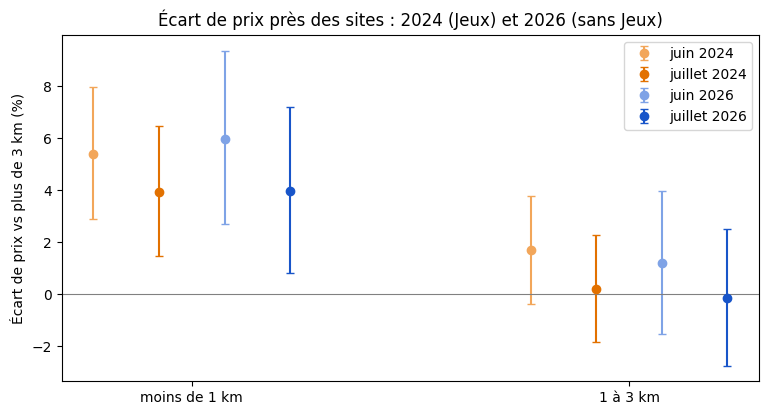

In [20]:
fig, ax = plt.subplots(figsize=(9, 4.5))
couleurs = {"juin 2024": "#f2a65a", "juillet 2024": "#e27100", "juin 2026": "#7fa3e6", "juillet 2026": "#1855c9"}
for i, (releve, couleur) in enumerate(couleurs.items()):
    e = comparaison.loc[releve]
    x = np.arange(len(e)) + (i - 1.5) * 0.15
    ax.errorbar(x, e["effet (%)"], yerr=[e["effet (%)"] - e["bas"], e["haut"] - e["effet (%)"]],
                fmt="o", capsize=3, color=couleur, label=releve)
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xticks(range(2), ["moins de 1 km", "1 à 3 km"])
ax.set_ylabel("Écart de prix vs plus de 3 km (%)")
ax.set_title("Écart de prix près des sites : 2024 (Jeux) et 2026 (sans Jeux)")
ax.legend()
plt.show()

### 3.1 La distance en continu

Au lieu de trois tranches, on découpe la distance en **tranches de 250 m**, jusqu'à 2,5 km. La référence est « plus de 2,5 km » (environ 12 % des annonces), plus fournie que « plus de 3 km ». On obtient une courbe de l'écart de prix en fonction de la distance, pour chaque relevé : elle montre **à quelle distance la prime disparaît**, sans fixer de seuil à l'avance.

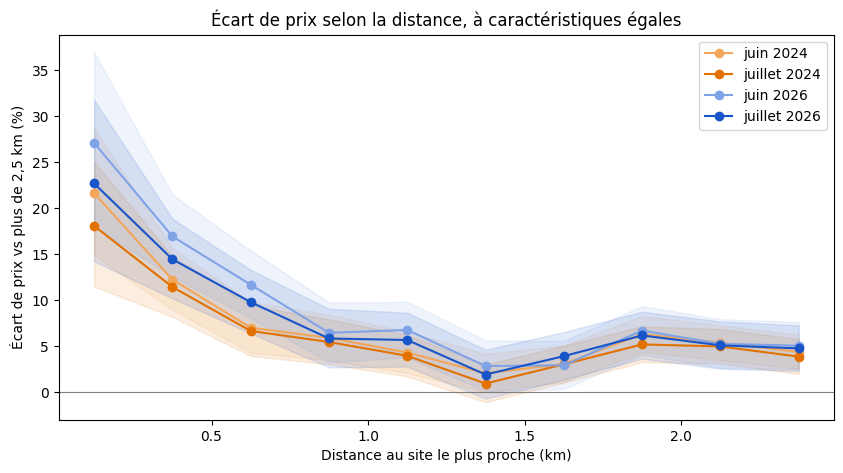

,juin 2024,juillet 2024,juin 2026,juillet 2026
distance (km),,,,
0.125,21.6,18.1,27.1,22.7
0.375,12.3,11.5,16.9,14.5
0.625,7.0,6.7,11.7,9.8
0.875,5.9,5.5,6.5,5.9
1.125,4.3,4.0,6.8,5.7
1.375,2.1,1.0,2.9,1.9
1.625,3.1,3.1,3.0,3.9
1.875,6.3,5.2,6.7,6.2
2.125,5.4,5.0,5.3,5.1


In [21]:
BORNES_FINES = list(np.arange(0, 2.51, 0.25)) + [np.inf]
ETIQUETTES_FINES = [f"{a:.2f}-{b:.2f} km" for a, b in zip(BORNES_FINES[:-2], BORNES_FINES[1:-1])] + ["plus de 2,5 km"]
FORMULE_FINE = FORMULE.replace("C(tranche, Treatment('plus de 3 km'))", "C(tranche_fine, Treatment('plus de 2,5 km'))")


def courbe_distance(df):
    df = df.copy()
    df["tranche_fine"] = pd.cut(df["dist_site_km"], bins=BORNES_FINES, labels=ETIQUETTES_FINES, right=False)
    m = smf.ols(FORMULE_FINE, data=df).fit(cov_type="HC1")
    ic = m.conf_int()
    lignes = []
    for a, etiquette in zip(BORNES_FINES[:-2], ETIQUETTES_FINES[:-1]):
        nom = f"C(tranche_fine, Treatment('plus de 2,5 km'))[T.{etiquette}]"
        lignes.append({"distance (km)": a + 0.125,
                       "effet (%)": (np.exp(m.params[nom]) - 1) * 100,
                       "bas": (np.exp(ic.loc[nom, 0]) - 1) * 100,
                       "haut": (np.exp(ic.loc[nom, 1]) - 1) * 100})
    return pd.DataFrame(lignes).set_index("distance (km)")


releves_courbe = {"juin 2024": donnees["juin"], "juillet 2024": donnees["juillet"],
                  "juin 2026": donnees_2026["juin"], "juillet 2026": donnees_2026["juillet"]}
courbes = {nom: courbe_distance(df) for nom, df in releves_courbe.items()}

fig, ax = plt.subplots(figsize=(10, 5))
for nom, c in courbes.items():
    ax.plot(c.index, c["effet (%)"], marker="o", color=couleurs[nom], label=nom)
    ax.fill_between(c.index, c["bas"], c["haut"], color=couleurs[nom], alpha=0.12)
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xlabel("Distance au site le plus proche (km)")
ax.set_ylabel("Écart de prix vs plus de 2,5 km (%)")
ax.set_title("Écart de prix selon la distance, à caractéristiques égales")
ax.legend()
plt.show()

pd.concat({nom: c["effet (%)"] for nom, c in courbes.items()}, axis=1).round(1)

**Commentaire** :

- **2024 contre 2026** : l'écart de prix à moins de 1 km d'un site est le même : +5,4 % en juin 2024, +4,0 % en juillet 2024, **+6,0 % en juin 2026** et **+4,0 % en juillet 2026**, avec des intervalles qui se recoupent largement. En 2026, il n'y a pas de Jeux, mais la « prime » est toujours là.
- **Juillet 2024** : sa courbe ne se détache pas des trois autres. Tout près des sites (moins de 250 m), c'est même la plus basse : +18 %, contre +22 % en juin 2024, +27 % en juin 2026 et +23 % en juillet 2026.
- **Forme de la courbe** : elle est la même pour les quatre relevés. L'écart est d'environ +20 % à moins de 250 m, +12 à 17 % entre 250 et 500 m, +7 à 12 % entre 500 et 750 m, puis il se stabilise autour de +2 à +7 % au-delà de 1 km. La prime décroît vite avec la distance : c'est un effet très local.
- **Conclusion** : la prime de prix mesurée à l'étape 1 vient de **l'emplacement**, pas des Jeux. Les sites des JO parisiens sont installés dans des lieux emblématiques (Tour Eiffel, Concorde, Invalides, Grand Palais, Champ-de-Mars), déjà recherchés par les touristes. Ce test placebo montre que la régression de l'étape 1 seule ne peut pas mesurer l'effet des Jeux.

Limites : les relevés 2026 contiennent environ deux fois moins d'annonces avec un prix, et deux ans séparent les deux étés (inflation, réglementation, évolution du parc).

## 4. Triple différence : l'été 2024 comparé à l'été 2026

À l'étape 2, les annonces proches et les témoins n'évoluaient pas de la même façon avant les Jeux : les quartiers touristiques ont leur propre saisonnalité. Pour la retirer, on compare l'été 2024 à l'été 2026, sans Jeux.

**Données** : relevés de juin, juillet, août et septembre, en 2024 et en 2026. Mêmes groupes qu'à l'étape 2 : proche (< 1 km) et témoin (> 2 km).

**Modèle :**

$$y_{it} = \sum_{m \in \{7,8,9\}} \Big[\gamma_m \cdot \text{proche}_i \cdot \mathbb{1}[\text{mois}=m] + \delta_m \cdot \text{proche}_i \cdot \mathbb{1}[\text{mois}=m] \cdot \mathbb{1}[2024]\Big] + \alpha_{i,\text{année}} + \lambda_t + \varepsilon_{it}$$

- **$\alpha_{i,\text{année}}$** : un effet fixe par annonce **et par année**. Chaque logement est comparé à lui-même au cours d'un même été, ce qui absorbe aussi l'évolution de son prix entre 2024 et 2026.
- **$\lambda_t$** : un effet fixe par mois de chaque année ; il retire ce qui touche tout Paris.
- **$\gamma_m$** : l'écart habituel entre proches et témoins le mois $m$, par rapport à juin. Il est mesuré sur les deux années, et c'est la saisonnalité propre aux quartiers touristiques.
- **$\delta_m$ : l'effet des Jeux**. C'est ce que 2024 a de plus que 2026 le mois $m$, par rapport à juin.

**Hypothèse** : sans les Jeux, l'écart saisonnier entre proches et témoins aurait été le même en 2024 et en 2026. **Limite** : juin 2024 sert de référence ; s'il était déjà touché par les Jeux (réservations anticipées), l'effet est sous-estimé.

In [22]:
MOIS_ETE = {"juin": 6, "juillet": 7, "aout": 8, "septembre": 9}

morceaux = []
for annee, charger in [(2024, charger_releve), (2026, charger_releve_2026)]:
    for mois, num in MOIS_ETE.items():
        r = charger(mois)
        r["annee"], r["mois"] = annee, num
        morceaux.append(r)
ete = pd.concat(morceaux, ignore_index=True).drop_duplicates(subset=["id", "annee", "mois"])

# Position fixe par annonce, puis groupes proche / témoin
pos_ete = ete.groupby("id")[["latitude", "longitude"]].median()
pos_ete["dist_site_km"], _ = distance_site_le_plus_proche(pos_ete, sites)
pos_ete["groupe"] = np.select([pos_ete["dist_site_km"] < 1, pos_ete["dist_site_km"] > 2],
                              ["proche", "témoin"], default="intermédiaire")
ete = ete.merge(pos_ete[["groupe"]], left_on="id", right_index=True)
ete = ete[ete["groupe"] != "intermédiaire"].copy()
ete["proche"] = (ete["groupe"] == "proche").astype(int)

# Variables : prix extrêmes retirés avec des bornes propres à chaque année
ete["prix"] = pd.to_numeric(ete["price"].str.replace(r"[$,]", "", regex=True), errors="coerce")
bornes = ete.groupby("annee")["prix"].quantile([0.01, 0.99]).unstack()
dans_bornes = ete["prix"].between(ete["annee"].map(bornes[0.01]), ete["annee"].map(bornes[0.99]))
ete["log_prix"] = np.log(ete["prix"].where(dans_bornes))
ete["occupation"] = 1 - ete["availability_30"] / 30
ete["avis_30j"] = ete["number_of_reviews_l30d"]

ete.groupby(["annee", "groupe"])["id"].nunique().unstack().rename_axis(None, axis=1)

,proche,témoin
annee,,
2024,22915,35544
2026,18640,26674


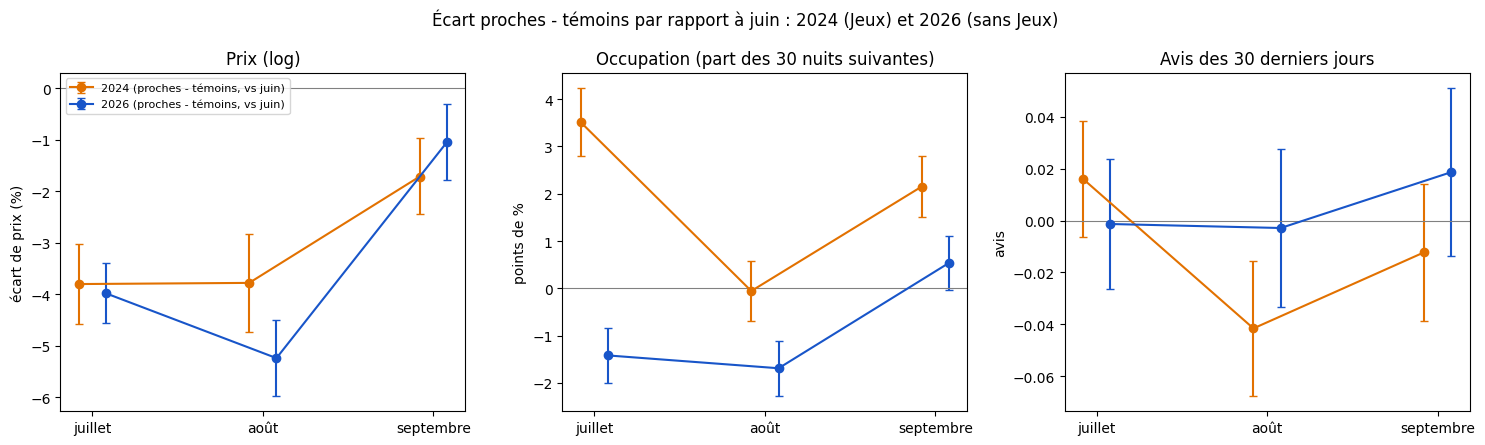

effet des Jeux  \
Prix (log)                               juillet             0.188   
                                         août                1.542   
                                         septembre          -0.676   
Occupation (part des 30 nuits suivantes) juillet             4.926   
                                         août                1.632   
                                         septembre           1.613   
Avis des 30 derniers jours               juillet             0.017   
                                         août               -0.039   
                                         septembre          -0.031   

                                                    bas IC 95 %  haut IC 95 %  \
Prix (log)                               juillet         -0.790         1.175   
                                         août             0.306         2.793   
                                         septembre       -1.721         0.381   
Occupation (part des 30 nuits suivantes) juillet          4.015         5.838   
                                         août             0.786         2.478   
                                         septembre        0.765         2.461   
Avis des 30 derniers jours               juillet         -0.016         0.050   
                                         août            -0.077        -0.001   
                                         septembre       -0.071         0.009   

                                                    p-valeur  
Prix (log)                               juillet       0.708  
                                         août          0.014  
                                         septembre     0.209  
Occupation (part des 30 nuits suivantes) juillet       0.000  
                                         août          0.000  
                                         septembre     0.000  
Avis des 30 derniers jours               juillet       0.302  
                                         août          0.046  
                                         septembre     0.130

In [23]:
VARIABLES_ETE = {k: v for k, v in VARIABLES.items() if k != "en_ligne"}


def triple_difference(var):
    d = ete.dropna(subset=[var]).copy()
    d["annonce_annee"] = pd.factorize(d["id"].astype(str) + "_" + d["annee"].astype(str))[0]
    d["periode"] = d["annee"] * 100 + d["mois"]
    d["cluster"] = pd.factorize(d["id"])[0]
    noms = []
    for m in [7, 8, 9]:
        d[f"proche × {m}"] = d["proche"] * (d["mois"] == m)
        d[f"proche × {m} × 2024"] = d[f"proche × {m}"] * (d["annee"] == 2024)
        noms += [f"proche × {m}", f"proche × {m} × 2024"]
    d = d.set_index(["annonce_annee", "periode"])
    return PanelOLS(d[var], d[noms], entity_effects=True, time_effects=True).fit(
        cov_type="clustered", clusters=d[["cluster"]])


def par_annee(var, annee):
    """Écart proches - témoins par rapport à juin, pour une seule année."""
    d = ete[(ete["annee"] == annee)].dropna(subset=[var]).copy()
    for m in [7, 8, 9]:
        d[f"proche × {m}"] = d["proche"] * (d["mois"] == m)
    d = d.set_index(["id", "mois"])
    return PanelOLS(d[var], d[[f"proche × {m}" for m in [7, 8, 9]]],
                    entity_effects=True, time_effects=True).fit(cov_type="clustered", cluster_entity=True)


NOMS_MOIS = {7: "juillet", 8: "août", 9: "septembre"}
resultats_td = {var: triple_difference(var) for var in VARIABLES_ETE}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
tableau_td = {}
for ax, var in zip(axes, VARIABLES_ETE):
    for annee, couleur in [(2024, "#e27100"), (2026, "#1855c9")]:
        r = par_annee(var, annee)
        effet = mise_a_echelle(var, r.params.to_numpy())
        ic = r.conf_int()
        ax.errorbar(np.array([7, 8, 9]) + (0.08 if annee == 2026 else -0.08), effet,
                    yerr=[effet - mise_a_echelle(var, ic["lower"].to_numpy()),
                          mise_a_echelle(var, ic["upper"].to_numpy()) - effet],
                    fmt="o-", capsize=3, color=couleur, label=f"{annee} (proches - témoins, vs juin)")
    ax.axhline(0, color="grey", linewidth=0.8)
    ax.set_xticks([7, 8, 9], ["juillet", "août", "septembre"])
    ax.set_title(VARIABLES[var])
    ax.set_ylabel(UNITES[var])
    r = resultats_td[var]
    noms = [f"proche × {m} × 2024" for m in [7, 8, 9]]
    tableau_td[VARIABLES[var]] = pd.DataFrame({
        "effet des Jeux": mise_a_echelle(var, r.params[noms]).to_numpy(),
        "bas IC 95 %": mise_a_echelle(var, r.conf_int().loc[noms, "lower"]).to_numpy(),
        "haut IC 95 %": mise_a_echelle(var, r.conf_int().loc[noms, "upper"]).to_numpy(),
        "p-valeur": r.pvalues[noms].to_numpy(),
    }, index=[NOMS_MOIS[m] for m in [7, 8, 9]])
axes[0].legend(fontsize=8)
fig.suptitle("Écart proches - témoins par rapport à juin : 2024 (Jeux) et 2026 (sans Jeux)")
fig.tight_layout()
plt.show()

pd.concat(tableau_td).round(3)

Le tableau donne **l'effet des Jeux** ($\delta_m$) : l'écart entre les deux courbes du graphique, avec son intervalle de confiance.

**Commentaire** :

- **Saisonnalité en 2026** : sans Jeux, les écarts entre proches et témoins ne sont pas nuls. Pour le prix, les annonces proches sont relativement moins chères qu'en juin : environ −4 % en juillet, −5 % en août et −1 % en septembre. L'occupation des annonces proches est un peu plus faible : environ −1,4 point en juillet et −1,7 en août. Les quartiers touristiques ont donc leur propre saisonnalité, avec un pic relatif en juin. C'est ce qui biaisait l'étape 2.
- **Effet des Jeux, une fois cette saisonnalité retirée** :
  - **Prix** : +0,2 % en juillet (non significatif), **+1,5 % en août** (IC 95 % : 0,3 à 2,8) et −0,7 % en septembre (non significatif). L'effet sur le prix est très faible, au mieux 1 à 2 % en août.
  - **Occupation** : **+4,9 points en juillet** (4,0 à 5,8), +1,6 point en août et +1,6 point en septembre, tous significatifs. Le relevé de mi-juillet couvre les 30 nuits suivantes, donc toute la période des JO : c'est là que l'effet est le plus fort. Celui de septembre correspond aux Jeux paralympiques.
  - **Avis** : aucun effet en juillet (+0,02, non significatif), un effet légèrement négatif en août (−0,04, p = 0,046) et rien en septembre. Il n'y a pas de hausse des séjours effectués propre aux annonces proches.
- **Comparaison avec l'étape 2** : l'étape 2 trouvait une baisse relative du prix pendant les JO (−3,8 % en juillet). Cette baisse était due à la saisonnalité, et elle disparaît avec la triple différence. L'effet sur l'occupation en juillet est confirmé, et même plus fort (+4,9 points contre +3,4).

Pendant les Jeux, les annonces proches des sites ont donc été **davantage réservées** que les témoins, mais leurs **prix ont à peine augmenté**. Les hôtes n'ont pas, en moyenne, profité des Jeux pour augmenter leurs prix davantage près des sites.

## 5. Les avis semaine par semaine, de 2022 à 2026

Les avis mesurent des **séjours réellement effectués** : un voyageur laisse un avis après son séjour, en général dans les deux semaines. Le fichier des avis d'Inside Airbnb donne la date de chaque avis depuis 2010. On peut donc :
- travailler **à la semaine**, et voir précisément les semaines des Jeux ;
- comparer **2024 aux autres années**, avant (2022, 2023) et après (2025, 2026) ;
- travailler **en distance continue**.

**Limite importante** : le fichier ne contient que les annonces encore en ligne en septembre 2026 (environ 37 % des annonces vues en 2024). Les annonces retirées depuis, par exemple celles créées pour les Jeux, n'y figurent pas. Ce biais touche toutes les années de la même façon, mais il faut le garder en tête.

Les positions des annonces viennent du relevé de septembre 2026.

In [24]:
avis = pd.read_csv(DOSSIER_EXTERNE / "reviews_2026-09-16.csv.gz", usecols=["listing_id", "date"], parse_dates=["date"])
pos_avis = pd.read_csv(DOSSIER_EXTERNE / "listings_2026-09-16.csv.gz", usecols=["id", "latitude", "longitude"]).set_index("id")
pos_avis["dist_site_km"], _ = distance_site_le_plus_proche(pos_avis, sites)

# Semaines complètes, du lundi 3 janvier 2022 au dimanche 6 septembre 2026
avis = avis[avis["date"].between("2022-01-03", "2026-09-06")]
avis = avis.merge(pos_avis[["dist_site_km"]], left_on="listing_id", right_index=True)
avis["annee"] = avis["date"].dt.isocalendar().year.astype(int)
avis["semaine_iso"] = avis["date"].dt.isocalendar().week.astype(int)
avis["semaine"] = avis["date"].dt.to_period("W-SUN").dt.start_time
avis["groupe"] = np.select([avis["dist_site_km"] < 1, avis["dist_site_km"] > 2], ["proche", "témoin"], default="intermédiaire")

avis.groupby("annee").size().rename("avis").to_frame().T

annee,2022,2023,2024,2025,2026
avis,235278,314708,373841,490109,412173


### 5.1 Part des avis laissés pour des annonces proches des sites

Chaque semaine, on calcule la part des avis qui concernent des annonces proches (< 1 km), parmi les avis des annonces proches et témoins (> 2 km). Utiliser une **part** plutôt qu'un nombre retire ce qui touche tout Paris (saison touristique, croissance d'Airbnb).

On compare ensuite 2024 aux autres années, **semaine par semaine** : l'écart entre 2024 et la moyenne de 2023 et 2025, les deux années voisines, mesure ce que l'été des Jeux a eu de particulier. Les Jeux olympiques correspondent aux semaines ISO 30 à 32 (26 juillet - 11 août), et les avis arrivent avec environ une à deux semaines de retard.

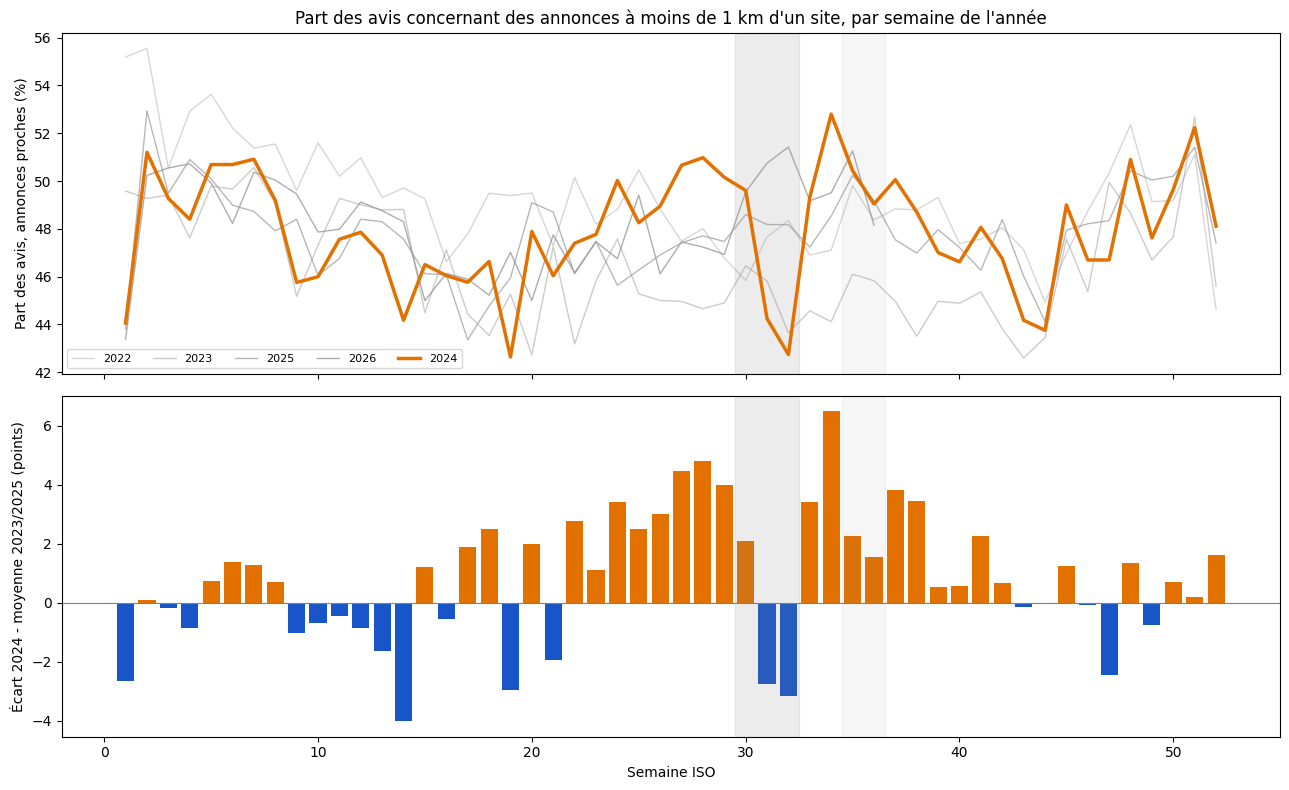

semaine_iso,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40
écart 2024 (points),2.48,-2.97,1.98,-1.94,2.75,1.12,3.41,2.48,2.99,4.47,4.8,3.97,2.08,-2.76,-3.17,3.42,6.48,2.27,1.53,3.8,3.46,0.54,0.56


In [25]:
comptes = avis[avis["groupe"] != "intermédiaire"].groupby(["annee", "semaine_iso", "groupe"]).size().unstack()
comptes = comptes[comptes.index.get_level_values("semaine_iso") <= 52]
part = (comptes["proche"] / comptes.sum(axis=1) * 100).unstack("annee")

ecart_2024 = part[2024] - part[[2023, 2025]].mean(axis=1)

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for annee in [2022, 2023, 2025, 2026]:
    axes[0].plot(part.index, part[annee], color="#999999", alpha=0.4 + 0.1 * (annee - 2022), linewidth=1, label=str(annee))
axes[0].plot(part.index, part[2024], color="#e27100", linewidth=2.5, label="2024")
axes[0].set_ylabel("Part des avis, annonces proches (%)")
axes[0].set_title("Part des avis concernant des annonces à moins de 1 km d'un site, par semaine de l'année")
axes[0].legend(ncol=5, fontsize=8)
axes[1].bar(ecart_2024.index, ecart_2024.values, color=np.where(ecart_2024 > 0, "#e27100", "#1855c9"))
axes[1].axhline(0, color="grey", linewidth=0.8)
axes[1].set_ylabel("Écart 2024 - moyenne 2023/2025 (points)")
axes[1].set_xlabel("Semaine ISO")
for ax in axes:
    ax.axvspan(29.5, 32.5, color="grey", alpha=0.15)
    ax.axvspan(34.5, 36.5, color="grey", alpha=0.07)
fig.tight_layout()
plt.show()

ecart_2024.loc[18:40].round(2).to_frame("écart 2024 (points)").T

### 5.2 Recherche des points de rupture

On cherche, sans les fixer à l'avance, le **début et la fin d'une période anormale** dans l'écart 2024 (graphique du bas). La méthode découpe l'année en trois morceaux (avant / pendant / après) avec une moyenne constante sur chacun. Elle essaie toutes les paires de semaines possibles comme ruptures et garde celle qui colle le mieux aux données, c'est-à-dire qui minimise la somme des carrés des écarts.

**Mise en garde** : la méthode trouve toujours deux ruptures, même s'il n'y a rien. Il faut donc regarder si la période trouvée est nette, si elle a un sens (les semaines des Jeux) et si son écart moyen est grand par rapport au bruit des autres semaines.

In [26]:
serie = ecart_2024.dropna()
valeurs, semaines = serie.to_numpy(), serie.index.to_numpy()


def sse(x):
    return ((x - x.mean()) ** 2).sum() if len(x) else 0.0


meilleur = min(
    ((sse(valeurs[:a]) + sse(valeurs[a:b]) + sse(valeurs[b:]), a, b)
     for a in range(2, len(valeurs) - 2) for b in range(a + 1, len(valeurs) - 1)),
    key=lambda t: t[0],
)
_, a, b = meilleur
print(f"Période anormale détectée : semaines ISO {semaines[a]} à {semaines[b - 1]}")
print(f"Écart moyen pendant cette période : {valeurs[a:b].mean():+.2f} points")
print(f"Écart moyen le reste de l'année   : {np.r_[valeurs[:a], valeurs[b:]].mean():+.2f} points "
      f"(écart-type semaine à semaine : {np.r_[valeurs[:a], valeurs[b:]].std():.2f})")

Période anormale détectée : semaines ISO 22 à 38
Écart moyen pendant cette période : +2.54 points
Écart moyen le reste de l'année   : -0.01 points (écart-type semaine à semaine : 1.52)


### 5.3 À quelle distance l'effet s'éteint-il ?

Pour chaque tranche de distance de 250 m, on compare le nombre d'avis pendant la fenêtre des Jeux à une période de référence de la même année :

$$R = \frac{\text{avis JO 2024} \;/\; \text{avis référence 2024}}{\text{avis JO 2023+2025} \;/\; \text{avis référence 2023+2025}}$$

- **Fenêtre des Jeux** : semaines ISO 31 à 34 (29 juillet - 25 août 2024), qui recouvrent les avis laissés pour les séjours des Jeux.
- **Référence** : semaines ISO 10 à 20 (mars - mi-mai). Elle est choisie **avant** la période anormale détectée en 5.2 (à partir de la semaine 22) : une référence en mai-juin serait déjà touchée par l'été 2024 particulier et fausserait la comparaison.
- $R > 1$ : à cette distance, il y a eu **plus de séjours que d'habitude** pendant les Jeux. $R = 1$ : rien de particulier.

L'intervalle de confiance suppose que les nombres d'avis suivent une loi de Poisson : $\text{Var}(\log R) \approx \sum 1/n$ sur les quatre comptages.

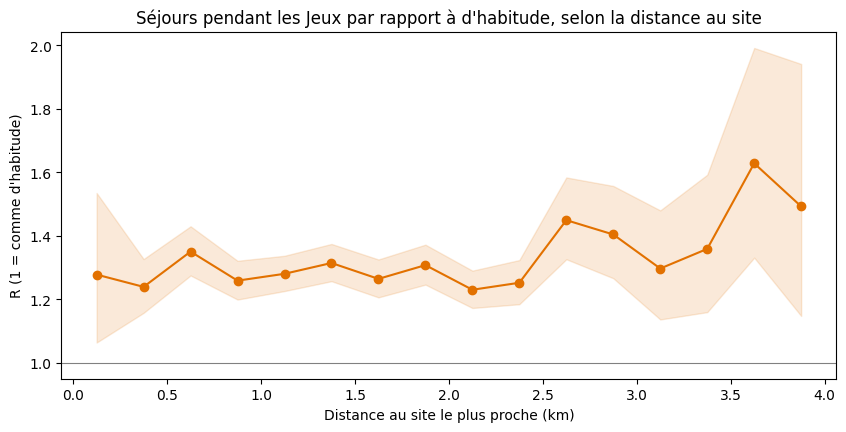

,R,bas,haut,avis JO 2024
tranche_250m,,,,
0.125,1.278,1.064,1.535,261
0.375,1.240,1.158,1.327,1812
0.625,1.351,1.276,1.430,2680
0.875,1.259,1.200,1.322,3601
1.125,1.281,1.226,1.338,4541
1.375,1.315,1.258,1.375,4309
1.625,1.265,1.207,1.326,3874
1.875,1.308,1.247,1.373,3713
2.125,1.231,1.173,1.291,3743


In [27]:
BORNES_AVIS = np.arange(0, 4.01, 0.25)
avis["tranche_250m"] = pd.cut(avis["dist_site_km"], bins=list(BORNES_AVIS) + [np.inf], right=False,
                              labels=list(BORNES_AVIS[:-1] + 0.125) + [4.125])
FENETRE_JO, FENETRE_REF = range(31, 35), range(10, 21)


def compter(annees, semaines):
    m = avis["annee"].isin(annees) & avis["semaine_iso"].isin(semaines)
    return avis[m].groupby("tranche_250m", observed=False).size()


j24, r24 = compter([2024], FENETRE_JO), compter([2024], FENETRE_REF)
jau, rau = compter([2023, 2025], FENETRE_JO), compter([2023, 2025], FENETRE_REF)
log_r = np.log(j24 / r24) - np.log(jau / rau)
erreur = np.sqrt(1 / j24 + 1 / r24 + 1 / jau + 1 / rau)
rapport = pd.DataFrame({"R": np.exp(log_r), "bas": np.exp(log_r - 1.96 * erreur),
                        "haut": np.exp(log_r + 1.96 * erreur), "avis JO 2024": j24})
rapport.index = rapport.index.astype(float)
rapport = rapport[rapport.index < 4]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(rapport.index, rapport["R"], marker="o", color="#e27100")
ax.fill_between(rapport.index, rapport["bas"], rapport["haut"], color="#e27100", alpha=0.15)
ax.axhline(1, color="grey", linewidth=0.8)
ax.set_xlabel("Distance au site le plus proche (km)")
ax.set_ylabel("R (1 = comme d'habitude)")
ax.set_title("Séjours pendant les Jeux par rapport à d'habitude, selon la distance au site")
plt.show()

rapport.round(3)

**Commentaire** :

- **Part des avis près des sites** : en 2024, elle est au-dessus des autres années de la fin mai à la mi-septembre. L'exception est les **semaines 31 et 32**, en plein cœur des JO (−2,8 et −3,2 points). Elle remonte fortement ensuite, en semaines 33 et 34 (+3,4 et +6,5 points). Les avis sont laissés une à deux semaines après le séjour. Les avis des semaines 33-34 correspondent donc aux séjours pendant les Jeux : ces séjours ont été relativement plus nombreux près des sites. Les avis des semaines 31-32 correspondent plutôt aux séjours juste avant et pendant la cérémonie d'ouverture, période où les périmètres de sécurité (pass Jeux le long de la Seine dès le 18 juillet) limitaient l'accès aux abords des sites. Ce n'est qu'une hypothèse.
- **Période anormale détectée** : semaines **22 à 38** (fin mai à mi-septembre), avec un écart moyen de +2,5 points, contre 0 le reste de l'année. La fin de cette période correspond aux Jeux paralympiques (fin le 8 septembre, semaine 36), avec le décalage des avis. Le début est en revanche bien antérieur aux JO (semaine 30). Possibles explications : séjours liés à la préparation des Jeux (équipes, délégations, médias), ou évolution non liée aux Jeux. L'effet reste modeste (+2,5 points sur une part d'environ 48 %), proche de la variabilité d'une semaine à l'autre (écart-type 1,5).
- **Distance** : le ratio R est compris entre 1,24 et 1,35 dans toutes les tranches jusqu'à 2,5 km. Pendant la fenêtre des Jeux, les avis ont augmenté d'environ 25 à 35 % de plus que d'habitude, **quelle que soit la distance aux sites**. Au-delà de 2,5 km, R est même un peu plus élevé (1,3 à 1,6, avec moins d'avis et des intervalles plus larges). Il n'y a pas de gradient : la hausse des séjours pendant les JO a touché **tout Paris**, pas seulement les abords des sites. La fenêtre des semaines 31 à 34 mélange en outre les semaines négatives (31-32) et positives (33-34) de la section 5.1, qui se compensent.
- **Comparaison avec le prix** : les résultats sont cohérents. Les Jeux ont surtout augmenté la demande de logements Airbnb dans l'ensemble de Paris (cohérent avec les +40 % de nuitées sur les plateformes en août 2024). L'effet propre aux annonces proches est faible : un peu plus d'occupation, presque pas de hausse de prix.

Limite : le fichier d'avis ne contient que les annonces encore en ligne en 2026, soit 37 % des annonces de 2024.

## 6. Conclusion

**Question** : les Jeux de 2024 ont-ils fait monter le prix des annonces Airbnb proches des sites de compétition ?

**Réponse : très peu.**

1. **Une prime de prix existe près des sites, mais elle vient de l'emplacement.** À caractéristiques égales, une annonce à moins de 1 km d'un site est 4 à 5 % plus chère (étape 1). On retrouve exactement la même prime à l'été 2026, sans Jeux (section 3). La prime décroît très vite avec la distance (environ +20 % à moins de 250 m, quelques % au-delà de 1 km), et cette courbe est identique en 2024 et en 2026.
2. **Une comparaison limitée à 2024 est trompeuse.** La différence de différences de l'étape 2 montre des tendances non parallèles avant les Jeux. Les quartiers proches des sites ont leur propre saisonnalité, avec un pic de prix relatif en juin.
3. **Une fois cette saisonnalité retirée grâce à 2026 (triple différence)**, l'effet des Jeux sur le prix des annonces proches est nul en juillet, d'environ +1,5 % en août, et nul en septembre. En revanche, leur **occupation** augmente nettement : +4,9 points pour les nuits de la période des JO, +1,6 point en août et en septembre.
4. **Les séjours (avis)** ont augmenté pendant les Jeux dans tout Paris, sans gradient de distance. Le contexte va dans le même sens : nuitées record sur les plateformes en août 2024, mais hôtels moins remplis en juin-juillet (effet d'éviction).

En résumé, les Jeux ont surtout **déplacé la demande** : moins de touristes habituels dans les hôtels, plus de séjours en location de courte durée dans tout Paris, un peu plus de réservations près des sites. Ils n'ont **pas entraîné de flambée des prix** près des sites. Les hôtes qui avaient anticipé une forte demande ont plutôt vu beaucoup de nuits rester libres pendant les JO (chute de l'occupation de juillet pour tous).

**Limites :**
- 2026 est deux ans plus tard (inflation, réglementation, parc d'annonces différent), et les relevés 2026 ont moins d'annonces avec un prix ;
- le prix observé est celui affiché au moment du relevé, pas le prix effectivement payé ;
- les avis ne couvrent que les annonces encore en ligne en 2026 (37 % de celles de 2024) ;
- la distance est mesurée à vol d'oiseau, à partir de positions volontairement décalées par Airbnb.